In [1]:
import re
import pickle
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

In [2]:
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
import tensorflow as tf
print(tf.config.list_physical_devices("GPU"))
!nvidia-smi

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Mon Sep 28 09:30:28 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   39C    P8              9W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |     

# Data Collection

In [4]:
URL = "https://www.gutenberg.org/cache/epub/1342/pg1342.txt"
raw_text = urllib.request.urlopen(URL).read().decode("utf-8")

# Remove Gutenberg header/footer

In [5]:
start = raw_text.find("*** START OF")
end = raw_text.find("*** END OF")
raw_text = raw_text[raw_text.find("\n", start) + 1 : end]

In [6]:
print("Characters:", len(raw_text))
print("Words (approx):", len(raw_text.split()))
print("\nSample:\n", raw_text[1000:1400])

Characters: 743287
Words (approx): 127360

Sample:
              House.        Cross Road.

                                London
                             George Allen.




             CHISWICK PRESS:--CHARLES WHITTINGHAM AND CO.
                  TOOKS COURT, CHANCERY LANE, LONDON.




                            [Illustration:

                          _To J. Comyns Carr
                      in acknowledgment of all I
  


# Text Cleaning

In [7]:
raw_text = raw_text.replace("\r", " ").replace("\n", " ")
sentences_raw = re.split(r"[.!?]+", raw_text)

In [8]:
def clean_sentence(s):
    s = s.lower()
    s = re.sub(r"[^a-z\s]", " ", s)
    s = re.sub(r"\s+", " ", s).strip()
    return s

In [9]:
sentences = [clean_sentence(s) for s in sentences_raw]
sentences = [s for s in sentences if len(s.split()) >= 2]

In [10]:
print("Total sentences:", len(sentences))
print("Example:", sentences[100])

Total sentences: 6985
Example: even now i do not think that it would be impossible to find persons especially female persons not necessarily of noble birth as overbearing as self centred as neglectful of good manners as lady catherine


# Tokenization

In [11]:
tokenizer = Tokenizer()
tokenizer.fit_on_texts(sentences)

In [12]:
vocab_size = len(tokenizer.word_index) + 1
print("Vocabulary size:", vocab_size)
print("Sample words:", list(tokenizer.word_index.items())[:10])

Vocabulary size: 6726
Sample words: [('the', 1), ('to', 2), ('of', 3), ('and', 4), ('her', 5), ('i', 6), ('a', 7), ('in', 8), ('was', 9), ('she', 10)]


# N-gram Sequences + Padding

In [13]:
MAX_SEQ_LEN = 12

In [14]:
sequences = []
for sent in sentences:
    tokens = tokenizer.texts_to_sequences([sent])[0]
    for i in range(1, len(tokens)):
        seq = tokens[max(0, i + 1 - MAX_SEQ_LEN) : i + 1]
        sequences.append(seq)

In [15]:
print("Total training sequences:", len(sequences))

Total training sequences: 121209


# Padding

In [16]:
padded = pad_sequences(sequences, maxlen=MAX_SEQ_LEN, padding="pre")
X = padded[:, :-1]
y = padded[:, -1]

In [17]:
print("X shape:", X.shape, "| y shape:", y.shape)

X shape: (121209, 11) | y shape: (121209,)


# Train / Validation Split

In [18]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.1, random_state=SEED
)
print("Train:", X_train.shape, "| Validation:", X_val.shape)

Train: (109088, 11) | Validation: (12121, 11)


# Model Building

In [24]:
model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=100, input_length=MAX_SEQ_LEN - 1),
    LSTM(256),
    Dropout(0.3),
    Dense(vocab_size, activation="softmax"),
])

In [25]:
model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy", tf.keras.metrics.SparseTopKCategoricalAccuracy(k=5, name="top5_acc")],
)

In [26]:
model.build(input_shape=(None, MAX_SEQ_LEN - 1))
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 11, 100)        │       672,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 256)            │       365,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6726)           │     1,728,582 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,766,750 (10.55 MB)

 Trainable params: 2,766,750 (10.55 MB)

 Non-trainable params: 0 (0.00 B)

# Training

In [27]:
callbacks = [
    EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=1, min_lr=1e-5),
]

In [28]:
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=40,
    batch_size=256,
    callbacks=callbacks,
    verbose=1,
)

Epoch 1/40
427/427 ━━━━━━━━━━━━━━━━━━━━ 7s 12ms/step - accuracy: 0.0467 - loss: 6.4473 - top5_acc: 0.1550 - val_accuracy: 0.0671 - val_loss: 6.1365 - val_top5_acc: 0.1801 - learning_rate: 0.0010
Epoch 2/40
427/427 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.0740 - loss: 5.9693 - top5_acc: 0.2046 - val_accuracy: 0.0854 - val_loss: 5.8554 - val_top5_acc: 0.2333 - learning_rate: 0.0010
Epoch 3/40
427/427 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.0986 - loss: 5.6559 - top5_acc: 0.2524 - val_accuracy: 0.1057 - val_loss: 5.6351 - val_top5_acc: 0.2744 - learning_rate: 0.0010
Epoch 4/40
427/427 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.1143 - loss: 5.4204 - top5_acc: 0.2815 - val_accuracy: 0.1174 - val_loss: 5.5201 - val_top5_acc: 0.2939 - learning_rate: 0.0010
Epoch 5/40
427/427 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.1252 - loss: 5.2409 - top5_acc: 0.3003 - val_accuracy: 0.1272 - val_loss: 5.4478 - val_top5_acc: 0.3048 - learning_rate: 0.0010
Epoch 6/40
427/427 ━━━━━━

# Accuracy Plot

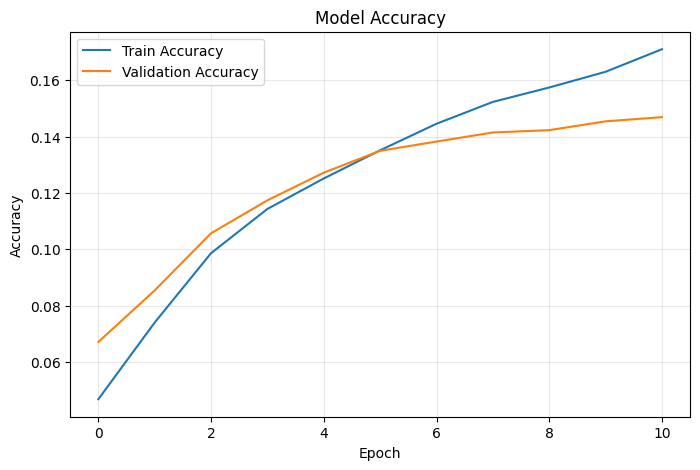

In [29]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Loss Plot

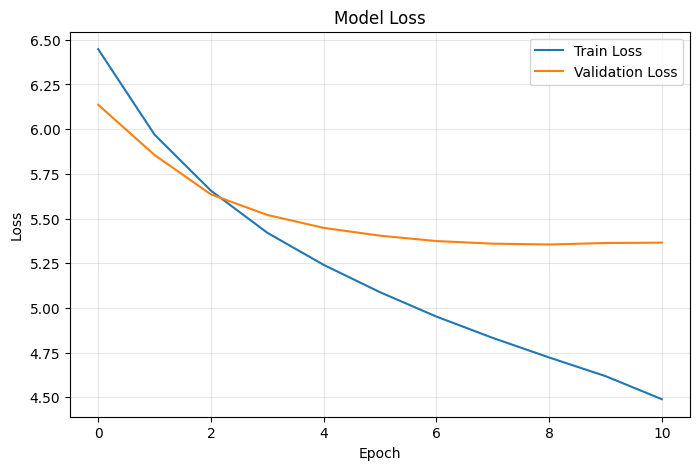

In [30]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Final Evaluation

In [31]:
val_loss, val_acc, val_top5 = model.evaluate(X_val, y_val, verbose=0)
print(f"Validation Loss      : {val_loss:.4f}")
print(f"Validation Accuracy  : {val_acc:.4f}")
print(f"Validation Top-5 Acc : {val_top5:.4f}")
print(f"Perplexity           : {np.exp(val_loss):.2f}")

Validation Loss      : 5.3550
Validation Accuracy  : 0.1423
Validation Top-5 Acc : 0.3273
Perplexity           : 211.65


# Next Word Prediction

In [32]:
index_word = {i: w for w, i in tokenizer.word_index.items()}

In [33]:
def predict_next_words(text, top_k=3):
    text = clean_sentence(text)
    tokens = tokenizer.texts_to_sequences([text])[0]
    if not tokens:
        return []
    tokens = tokens[-(MAX_SEQ_LEN - 1):]
    padded_in = pad_sequences([tokens], maxlen=MAX_SEQ_LEN - 1, padding="pre")
    probs = model.predict(padded_in, verbose=0)[0]
    probs[0] = 0  # ignore padding index
    top_idx = np.argsort(probs)[-top_k:][::-1]
    return [(index_word[i], float(probs[i])) for i in top_idx]

In [34]:
tests = [
    "it is a truth universally",
    "mr darcy was",
    "elizabeth felt that she",
    "i have not the pleasure of",
]
for t in tests:
    print(f"\nInput: '{t}'")
    for word, p in predict_next_words(t):
        print(f"   -> {word:<12} {p:.3f}")


Input: 'it is a truth universally'
   -> to           0.017
   -> said         0.013
   -> very         0.011

Input: 'mr darcy was'
   -> to           0.059
   -> a            0.054
   -> the          0.026

Input: 'elizabeth felt that she'
   -> had          0.261
   -> was          0.157
   -> could        0.088

Input: 'i have not the pleasure of'
   -> the          0.067
   -> my           0.056
   -> his          0.042


# Text Generation

In [35]:
def generate_text(seed_text, n_words=15, temperature=0.8):
    result = clean_sentence(seed_text)
    for _ in range(n_words):
        tokens = tokenizer.texts_to_sequences([result])[0][-(MAX_SEQ_LEN - 1):]
        padded_in = pad_sequences([tokens], maxlen=MAX_SEQ_LEN - 1, padding="pre")
        probs = model.predict(padded_in, verbose=0)[0].astype("float64")
        probs[0] = 0
        probs = np.log(probs + 1e-9) / temperature
        probs = np.exp(probs)
        probs /= probs.sum()
        next_id = np.random.choice(len(probs), p=probs)
        result += " " + index_word[next_id]
    return result

In [36]:
for seed in ["it is a truth", "mr bennet said", "elizabeth was", "she could not help"]:
    print("\n", generate_text(seed))


 it is a truth of receiving me as i have a visitor before he was wise at a most

 mr bennet said i will have been on what i will not know lydia and so good of

 elizabeth was really in the privilege of them in the dining room the former of general for

 she could not help dance and on her own reasons she chooses in their sum to be to be


# Save Model + Tokenizer

In [37]:
model.save("next_word_model.keras")
with open("tokenizer.pkl", "wb") as f:
    pickle.dump(tokenizer, f)
with open("config.pkl", "wb") as f:
    pickle.dump({"max_seq_len": MAX_SEQ_LEN}, f)
print("Saved: next_word_model.keras, tokenizer.pkl, config.pkl")

Saved: next_word_model.keras, tokenizer.pkl, config.pkl


# Download Files

In [38]:
from google.colab import files
files.download("next_word_model.keras")
files.download("tokenizer.pkl")
files.download("config.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>